## R1 - `logistic.py`

In [1]:
%%writefile logistic.py
import numpy as np

try:  # only so sklearn's Pipeline accepts the estimator
    from sklearn.base import BaseEstimator
except ImportError:  # pragma: no cover
    class BaseEstimator:  # type: ignore
        pass


def _sigmoid(z):
    """Numerically stable logistic function (no overflow at z = +-1000)."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))      # exp of a non-positive number
    e = np.exp(z[~pos])                           # exp of a negative number
    out[~pos] = e / (1.0 + e)
    return out


def _loss_from_logits(z, y):
    """Per-sample log-loss from logits: log(1+e^z) - y*z, stable for any |z|."""
    return np.logaddexp(0.0, z) - y * z


class LogisticClassifier(BaseEstimator):
    def __init__(self, lr=0.1, steps=1000, l2=0.0, class_weight=None, tol=1e-9, accelerate=False):
        self.lr = lr
        self.steps = steps
        self.l2 = l2
        self.class_weight = class_weight
        self.tol = tol                  # stop when ||gradient||_2 <= tol
        self.accelerate = accelerate    # Nesterov momentum with gradient restart (optional)

    # ---------- validation ----------
    @staticmethod
    def _check_X(X):
        try:
            X = np.asarray(X, dtype=float)
        except (TypeError, ValueError) as e:
            raise ValueError(f"X must be numeric and rectangular: {e}") from e
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        if X.ndim != 2:
            raise ValueError(f"X must be 1-D or 2-D, got {X.ndim}-D")
        if X.shape[0] == 0 or X.shape[1] == 0:
            raise ValueError("X is empty")
        if np.isnan(X).any():
            raise ValueError("X contains NaN")
        if np.isinf(X).any():
            raise ValueError("X contains inf")
        return X

    @classmethod
    def _check_Xy(cls, X, y):
        X = cls._check_X(X)
        try:
            y = np.asarray(y, dtype=float).ravel()
        except (TypeError, ValueError) as e:
            raise ValueError(f"y must be numeric: {e}") from e
        if np.isnan(y).any():
            raise ValueError("y contains NaN")
        if not np.all((y == 0) | (y == 1)):
            raise ValueError(f"labels must be in {{0, 1}}, found {np.unique(y)[:5]}")
        if len(y) != X.shape[0]:
            raise ValueError(f"X has {X.shape[0]} rows but y has {len(y)} labels")
        return X, y

    # ---------- weights, loss, gradient ----------
    def _sample_weights(self, y):
        n = len(y)
        cw = self.class_weight
        if cw is None:
            return np.ones(n)
        n1 = y.sum(); n0 = n - n1
        if cw == "balanced":
            if n1 == 0 or n0 == 0:
                raise ValueError("class_weight='balanced' needs both classes present")
            per_class = {0: n / (2 * n0), 1: n / (2 * n1)}
        elif isinstance(cw, dict):
            per_class = {0: float(cw.get(0, 1.0)), 1: float(cw.get(1, 1.0))}
        else:
            raise ValueError("class_weight must be None, 'balanced' or a dict {0: w0, 1: w1}")
        sw = np.where(y == 1, per_class[1], per_class[0])
        return sw / sw.mean()                       # normalised to mean weight 1

    @staticmethod
    def _design(X):
        return np.column_stack([np.ones(X.shape[0]), X])

    def _loss_grad(self, Xb, y, w, sw):
        n = len(y)
        z = Xb @ w
        loss = np.mean(sw * _loss_from_logits(z, y)) + 0.5 * self.l2 * np.dot(w[1:], w[1:])
        g = Xb.T @ (sw * (_sigmoid(z) - y)) / n
        g[1:] += self.l2 * w[1:]                    # intercept (index 0) is never penalised
        return loss, g

    def loss(self, X, y, w=None, sample_weight=None):
        """Objective at parameter vector w (defaults to the fitted one)."""
        X, y = self._check_Xy(X, y)
        w = self.w if w is None else np.asarray(w, float)
        sw = self._sample_weights(y) if sample_weight is None else sample_weight
        return self._loss_grad(self._design(X), y, w, sw)[0]

    def gradient(self, X, y, w=None, sample_weight=None):
        """Analytic gradient X_b^T (p - y)/n (+ l2 term) at w."""
        X, y = self._check_Xy(X, y)
        w = self.w if w is None else np.asarray(w, float)
        sw = self._sample_weights(y) if sample_weight is None else sample_weight
        return self._loss_grad(self._design(X), y, w, sw)[1]

    @classmethod
    def safe_lr(cls, X, y=None, l2=0.0, class_weight=None):
        """1/L, where L bounds the curvature: 0.25 * lambda_max(X_b^T diag(sw) X_b / n) + l2."""
        X = cls._check_X(X)
        sw = np.ones(X.shape[0]) if y is None else cls(class_weight=class_weight)._sample_weights(np.asarray(y, float))
        Xb = cls._design(X)
        lam = np.linalg.eigvalsh((Xb * sw[:, None]).T @ Xb / X.shape[0])[-1]
        return float(1.0 / (0.25 * lam + l2))

    # ---------- fitting ----------
    def fit(self, X, y):
        X, y = self._check_Xy(X, y)
        if y.min() == y.max():
            raise ValueError("y contains a single class; need both 0 and 1")
        if self.l2 < 0:
            raise ValueError("l2 must be >= 0")
        Xb, sw = self._design(X), self._sample_weights(y)
        w = np.zeros(Xb.shape[1])
        v, k = w.copy(), 1                          # momentum point and momentum counter
        self.converged_at, self.converged = None, False
        self.loss_history_ = []
        for step in range(self.steps + 1):
            loss, g = self._loss_grad(Xb, y, v if self.accelerate else w, sw)
            if step % 50 == 0:
                self.loss_history_.append((step, loss))
            if np.linalg.norm(g) <= self.tol:       # converged after `step` updates
                if self.accelerate:
                    w = v
                self.converged_at, self.converged = step, True
                break
            if step == self.steps:
                if self.accelerate:
                    w = v
                break
            if self.accelerate:
                w_new = v - self.lr * g
                if g @ (w_new - w) > 0:             # gradient restart: momentum is hurting
                    k = 1
                beta = (k - 1) / (k + 2)
                v = w_new + beta * (w_new - w)
                w, k = w_new, k + 1
            else:
                w = w - self.lr * g
        self.w = w
        self.n_steps_ = step
        self.final_grad_norm_ = float(np.linalg.norm(g))
        return self

    # ---------- inference ----------
    @property
    def intercept_(self):
        return float(self.w[0])

    @property
    def coef_(self):
        return self.w[1:]

    def decision_function(self, X):
        if not hasattr(self, "w"):
            raise RuntimeError("call fit() first")
        X = self._check_X(X)
        if X.shape[1] != len(self.w) - 1:
            raise ValueError(f"X has {X.shape[1]} features, model was fit with {len(self.w) - 1}")
        return self.w[0] + X @ self.w[1:]

    def predict_proba(self, X):
        """P(y = 1 | x), shape (n,)."""
        return _sigmoid(self.decision_function(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y, threshold=0.5):
        X, y = self._check_Xy(X, y)
        return float(np.mean(self.predict(X, threshold) == y))


Writing logistic.py


## R1 / R2 - tests (error cases, stability, gradient check)

In [2]:
%%writefile test_logistic.py
"""Run with: python3 test_logistic.py   (needs logistic.py in the same folder)
Covers R1 (error cases, stability, intercept, class_weight, convergence record) and R2 (gradient check)."""
import warnings
import numpy as np
from logistic import LogisticClassifier, _sigmoid, _loss_from_logits

warnings.simplefilter("error")          # any RuntimeWarning (overflow, log(0)) becomes a test failure
results = []


def record(name, ok, detail=""):
    results.append((name, bool(ok)))
    print(("PASS" if ok else "FAIL"), name, detail)


def raises_value_error(name, fn):
    try:
        fn()
    except ValueError as e:
        record(name, True, f"-> {e}")
    except Exception as e:
        record(name, False, f"wrong exception {type(e).__name__}")
    else:
        record(name, False, "no exception raised")


def make(n=400, p=4, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, p))
    y = (rng.uniform(size=n) < _sigmoid(X @ rng.normal(size=p) - 1.0)).astype(float)
    return X, y


X, y = make()

# ---- R1: error cases -------------------------------------------------------
raises_value_error("labels outside {0,1} (label 2)", lambda: LogisticClassifier().fit(X, np.where(y == 1, 2, 0)))
raises_value_error("labels outside {0,1} (labels -1/+1)", lambda: LogisticClassifier().fit(X, np.where(y == 1, 1, -1)))
raises_value_error("mismatched lengths", lambda: LogisticClassifier().fit(X, y[:-1]))
Xn = X.copy(); Xn[5, 1] = np.nan
raises_value_error("NaN in X", lambda: LogisticClassifier().fit(Xn, y))
yn = y.copy(); yn[0] = np.nan
raises_value_error("NaN in y", lambda: LogisticClassifier().fit(X, yn))
raises_value_error("single-class y", lambda: LogisticClassifier().fit(X, np.zeros(len(y))))
raises_value_error("class_weight invalid string", lambda: LogisticClassifier(class_weight="bal").fit(X, y))

# ---- R1: numerical stability ----------------------------------------------
s = _sigmoid(np.array([-1000.0, 1000.0, 0.0, -745.0, 745.0]))
record("sigmoid(+-1000) finite, exactly 0/1, sigmoid(0)=0.5", np.all(np.isfinite(s)) and s[0] == 0 and s[1] == 1 and s[2] == 0.5)
ll = _loss_from_logits(np.array([-1000.0, 1000.0, -1000.0, 1000.0]), np.array([0.0, 1.0, 1.0, 0.0]))
record("loss at z=+-1000: right side 0, wrong side = 1000 (finite)", np.allclose(ll, [0, 0, 1000, 1000]))
Xbig = X * 1e4                                       # logits in the thousands
m_big = LogisticClassifier(lr=1e-9, steps=50).fit(Xbig, y)
pb = m_big.predict_proba(Xbig)
record("fit + predict_proba on huge features: no NaN/inf", np.all(np.isfinite(m_big.w)) and np.all(np.isfinite(pb)))
record("predict_proba stays within [0,1] at extreme logits", pb.min() >= 0 and pb.max() <= 1)
record("loss() finite at extreme logits", np.isfinite(m_big.loss(Xbig, y)))

# ---- R1: intercept never regularised --------------------------------------
m_pen = LogisticClassifier(lr=LogisticClassifier.safe_lr(X, y, 50.0), steps=100000, l2=50.0, tol=1e-11).fit(X, y)
m_free = LogisticClassifier(lr=LogisticClassifier.safe_lr(X, y, 0.0), steps=100000, l2=0.0, tol=1e-11).fit(X, y)
gap = abs(m_pen.predict_proba(X).mean() - y.mean())
record("heavy l2 shrinks weights but mean(p) still equals base rate (intercept unpenalised)",
       m_pen.converged and np.linalg.norm(m_pen.coef_) < 0.2 * np.linalg.norm(m_free.coef_) and gap < 1e-8,
       f"(|mean(p)-mean(y)|={gap:.1e}, ||w|| {np.linalg.norm(m_pen.coef_):.3f} vs {np.linalg.norm(m_free.coef_):.3f} unpenalised)")
w0 = np.array([0.3, 1.0, -2.0, 0.5, 0.1])
g_a = LogisticClassifier(l2=0.0).gradient(X, y, w0)
g_b = LogisticClassifier(l2=5.0).gradient(X, y, w0)
record("l2 term touches gradient of weights, never of the intercept",
       g_a[0] == g_b[0] and np.allclose(g_b[1:] - g_a[1:], 5.0 * w0[1:]))

# ---- R1: class_weight -----------------------------------------------------
yi = (np.arange(1000) < 70).astype(float)            # 7% positives
sw = LogisticClassifier(class_weight="balanced")._sample_weights(yi)
record("balanced weights have mean exactly 1", abs(sw.mean() - 1) < 1e-12, f"(mean={sw.mean():.15f})")
record("balanced: positives weighted n0/n1 times more than negatives",
       abs(sw[0] / sw[-1] - (1000 - 70) / 70) < 1e-9)
sw_d = LogisticClassifier(class_weight={0: 1, 1: 10})._sample_weights(yi)
record("dict class_weight also normalised to mean 1", abs(sw_d.mean() - 1) < 1e-12)

# ---- R1: convergence record ----------------------------------------------
lr = LogisticClassifier.safe_lr(X, y, 1e-3)
m_ok = LogisticClassifier(lr=lr, steps=100000, l2=1e-3, tol=1e-9).fit(X, y)
record("converged run records converged=True and the step", m_ok.converged and m_ok.converged_at == m_ok.n_steps_ and m_ok.converged_at > 0,
       f"(converged_at={m_ok.converged_at}, ||g||={m_ok.final_grad_norm_:.1e})")
m_no = LogisticClassifier(lr=lr, steps=5, l2=1e-3, tol=1e-9).fit(X, y)
record("run that hits max steps records converged=False, converged_at=None", (not m_no.converged) and m_no.converged_at is None)
m_acc = LogisticClassifier(lr=lr, steps=100000, l2=1e-3, tol=1e-9, accelerate=True).fit(X, y)
record("accelerated solver reaches the same solution", np.max(np.abs(m_acc.w - m_ok.w)) < 1e-6 and m_acc.converged_at < m_ok.converged_at,
       f"(steps {m_acc.converged_at} vs {m_ok.converged_at})")

# ---- R2: gradient check (five parameter vectors, worst error each) --------
p_ = X.shape[1] + 1
rng = np.random.default_rng(7)
vectors = {"zero vector": np.zeros(p_), "small random": rng.normal(size=p_) * 0.1, "random": rng.normal(size=p_),
           "intercept only": np.r_[3.0, np.zeros(p_ - 1)], "far from optimum": rng.normal(size=p_) * 8}
clf = LogisticClassifier()
for name, w in vectors.items():
    g = clf.gradient(X, y, w)
    num = np.empty(p_)
    for j in range(p_):
        e = np.zeros(p_); e[j] = 1e-6
        num[j] = (clf.loss(X, y, w + e) - clf.loss(X, y, w - e)) / 2e-6
    worst = np.max(np.abs(g - num))
    record(f"gradient check [{name}]", worst < 1e-7, f"(worst abs error {worst:.2e})")
w = rng.normal(size=p_)
cw = LogisticClassifier(l2=0.7, class_weight="balanced")
g = cw.gradient(X, y, w); num = np.empty(p_)
for j in range(p_):
    e = np.zeros(p_); e[j] = 1e-6
    num[j] = (cw.loss(X, y, w + e) - cw.loss(X, y, w - e)) / 2e-6
record("gradient check [with l2 and balanced weights]", np.max(np.abs(g - num)) < 1e-7, f"(worst abs error {np.max(np.abs(g - num)):.2e})")

# ---- misc ------------------------------------------------------------------
raises_value_error("predict with wrong number of features", lambda: m_ok.predict_proba(X[:, :2]))
record("predict(threshold) is monotone in threshold", m_ok.predict(X, 0.2).sum() >= m_ok.predict(X, 0.5).sum() >= m_ok.predict(X, 0.8).sum())
record("list / 1-D input accepted", LogisticClassifier(lr=0.1, steps=10).fit(X[:, 0].tolist(), y.tolist()).w.shape == (2,))

n_ok = sum(ok for _, ok in results)
print(f"\n{n_ok}/{len(results)} checks passed")
raise SystemExit(0 if n_ok == len(results) else 1)


Writing test_logistic.py


In [3]:
!python test_logistic.py | tail -n 12

PASS accelerated solver reaches the same solution (steps 43 vs 110)
PASS gradient check [zero vector] (worst abs error 1.03e-10)
PASS gradient check [small random] (worst abs error 2.43e-11)
PASS gradient check [random] (worst abs error 9.29e-11)
PASS gradient check [intercept only] (worst abs error 2.06e-10)
PASS gradient check [far from optimum] (worst abs error 4.18e-10)
PASS gradient check [with l2 and balanced weights] (worst abs error 8.19e-10)
PASS predict with wrong number of features -> X has 2 features, model was fit with 4
PASS predict(threshold) is monotone in threshold 
PASS list / 1-D input accepted 

29/29 checks passed


## R4 - Data: real, imbalanced, split first

In [4]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from logistic import LogisticClassifier, _loss_from_logits, _sigmoid
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEED = 42

bank = fetch_openml(data_id=1461, as_frame=True, parser="auto")
X_all, y_raw = bank.data.copy(), bank.target
pos_label = y_raw.value_counts().idxmin()                 # minority class = the positive class
y_all = (y_raw == pos_label).astype(int).values
for c in ("duration", "V12"):                             # call duration is only known AFTER the call: leakage
    if c in X_all.columns:
        X_all = X_all.drop(columns=c)
        print(f"dropped '{c}' (call duration is not known before calling the customer)")
        break
cat_cols = [c for c in X_all.columns if not pd.api.types.is_numeric_dtype(X_all[c])]
num_cols = [c for c in X_all.columns if c not in cat_cols]
X_all[cat_cols] = X_all[cat_cols].astype(object)

pos_rate = y_all.mean()
print(f"rows={len(X_all):,}  features={X_all.shape[1]} ({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print(f"positive rate = {pos_rate:.2%}   ->   accuracy of 'always predict negative' = {1 - pos_rate:.2%}")

# SPLIT FIRST (60/20/20, stratified). Test is not touched until the evaluation cells.
X_tmp, X_te, y_tmp, y_te = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
print(f"train={len(X_tr):,} val={len(X_va):,} test={len(X_te):,}")

def make_prep():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

L2 = 1e-3
def fit_pipeline(class_weight=None, l2=L2):
    """Preprocessing lives inside the Pipeline; it is fit on the training split only."""
    Xm = make_prep().fit(X_tr).transform(X_tr)
    lr = LogisticClassifier.safe_lr(Xm, y_tr, l2, class_weight)
    clf = LogisticClassifier(lr=lr, steps=200_000, l2=l2, class_weight=class_weight, tol=1e-9, accelerate=True)
    return Pipeline([("prep", make_prep()), ("clf", clf)]).fit(X_tr, y_tr)

dropped 'V12' (call duration is not known before calling the customer)
rows=45,211  features=15 (6 numeric, 9 categorical)
positive rate = 11.70%   ->   accuracy of 'always predict negative' = 88.30%
train=27,126 val=9,042 test=9,043


## R2 - Gradient check (before any training)
Analytic `X_b^T (p - y)/n` vs a central-difference numerical gradient, at five parameter vectors, on the real preprocessed training matrix.

In [5]:
Xtr_m = make_prep().fit(X_tr).transform(X_tr)
P = Xtr_m.shape[1] + 1
rng = np.random.default_rng(7)
vecs = {"zero vector": np.zeros(P), "small random (x0.1)": rng.normal(size=P) * 0.1, "random (x1)": rng.normal(size=P),
        "intercept = logit(base rate)": np.r_[np.log(y_tr.mean() / (1 - y_tr.mean())), np.zeros(P - 1)],
        "far from optimum (x5)": rng.normal(size=P) * 5}
gc = LogisticClassifier()
rows = []
for name, w in vecs.items():
    g = gc.gradient(Xtr_m, y_tr, w)
    num = np.array([(gc.loss(Xtr_m, y_tr, w + e) - gc.loss(Xtr_m, y_tr, w - e)) / 2e-6 for e in np.eye(P) * 1e-6])
    rows.append({"parameter vector": name, "worst abs error": np.max(np.abs(g - num)), "||gradient||": np.linalg.norm(g)})
grad_table = pd.DataFrame(rows).set_index("parameter vector")
grad_table.map(lambda v: f"{v:.3e}")

,worst abs error,||gradient||
parameter vector,,
zero vector,1.325e-10,7.129e-01
small random (x0.1),6.803e-11,5.829e-01
random (x1),2.039e-10,6.828e-01
intercept = logit(base rate),7.487e-11,7.553e-02
far from optimum (x5),9.263e-10,7.143e-01


## R3 - Reconciliation with scikit-learn
Same preprocessed training matrix for both models. Parameter difference = max |w_mine - w_sklearn| over intercept and all weights; probability difference = max |p_mine - p_sklearn| on the training rows.
sklearn minimises `C*sum(loss) + 0.5*||w||^2`; ours is `mean(loss) + 0.5*l2*||w[1:]||^2`, so **l2 = 1/(C*n)**.

In [6]:
Xm, n = Xtr_m, len(y_tr)
C = 1.0

def mine(l2, tol, steps, accel=True):
    lr = LogisticClassifier.safe_lr(Xm, y_tr, l2)
    return LogisticClassifier(lr=lr, steps=steps, l2=l2, tol=tol, accelerate=accel).fit(Xm, y_tr)

def sk_fit(**kw):
    m = LogisticRegression(**kw).fit(Xm, y_tr)
    return m, np.r_[m.intercept_, m.coef_.ravel()], m.predict_proba(Xm)[:, 1]

def gap(my, w_sk, p_sk):
    return np.max(np.abs(my.w - w_sk)), np.max(np.abs(my.predict_proba(Xm) - p_sk))

rec = []
def add(step, sk_desc, my_desc, my, w_sk, p_sk):
    dw, dp = gap(my, w_sk, p_sk)
    rec.append({"step": step, "sklearn": sk_desc, "mine": my_desc, "max |dw|": dw, "max |dp|": dp})

l2m = 1.0 / (C * n)
TIGHT = 1e-12
sk_ref, w_ref, p_ref = sk_fit(solver="lbfgs", tol=TIGHT, max_iter=20000)     # sklearn, C=1, tight: the reference solution
# 0. raw comparison: sklearn defaults vs my defaults (no regularisation), mine run to convergence
_, w0, p0 = sk_fit()
m_l2_0 = mine(0.0, TIGHT, 100_000)
add("0 raw defaults", "LogisticRegression() defaults: C=1, lbfgs, tol=1e-4, max_iter=100", "l2=0 (converged)", m_l2_0, w0, p0)
# 1. strength + convention, measured against sklearn at C=1 with tight tolerance (isolates the l2 translation)
add("1a no regularisation", "C=1, lbfgs, tol=1e-12", "l2=0", m_l2_0, w_ref, p_ref)
add("1b strength matched, WRONG convention", "C=1, lbfgs, tol=1e-12", "l2 = 1/C (forgot the 1/n)", mine(1.0 / C, TIGHT, 100_000), w_ref, p_ref)
my_tight = mine(l2m, TIGHT, 100_000)
add("1c strength + convention matched", "C=1, lbfgs, tol=1e-12", "l2 = 1/(C*n)", my_tight, w_ref, p_ref)
# 2. intercept convention: liblinear PENALISES the intercept, lbfgs does not
_, w_lib, p_lib = sk_fit(solver="liblinear", tol=TIGHT, max_iter=20000)
add("2a intercept penalised (liblinear)", "solver=liblinear, tol=1e-12", "l2=1/(C*n); intercept unpenalised", my_tight, w_lib, p_lib)
add("2b intercept unpenalised (lbfgs)", "solver=lbfgs, tol=1e-12", "l2=1/(C*n); intercept unpenalised", my_tight, w_ref, p_ref)
# 3. tighten BOTH tolerances step by step
for t in (1e-4, 1e-6, 1e-8, 1e-10, 1e-12):
    _, w_t, p_t = sk_fit(solver="lbfgs", tol=t, max_iter=20000)
    m_t = mine(l2m, t, 100_000)
    add(f"3 both tolerances = {t:.0e}", f"lbfgs tol={t:.0e}", f"l2=1/(C*n), tol={t:.0e}, converged_at={m_t.converged_at}", m_t, w_t, p_t)
rec_df = pd.DataFrame(rec).set_index("step")
rec_df.assign(**{"max |dw|": rec_df["max |dw|"].map("{:.2e}".format), "max |dp|": rec_df["max |dp|"].map("{:.2e}".format)})

,sklearn,mine,max |dw|,max |dp|
step,,,,
0 raw defaults,"LogisticRegression() defaults: C=1, lbfgs, tol...",l2=0 (converged),4.62e-02,1.19e-02
1a no regularisation,"C=1, lbfgs, tol=1e-12",l2=0,2.74e-02,7.64e-03
"1b strength matched, WRONG convention","C=1, lbfgs, tol=1e-12",l2 = 1/C (forgot the 1/n),2.19e+00,8.02e-01
1c strength + convention matched,"C=1, lbfgs, tol=1e-12",l2 = 1/(C*n),7.91e-06,2.70e-06
2a intercept penalised (liblinear),"solver=liblinear, tol=1e-12",l2=1/(C*n); intercept unpenalised,3.19e-02,4.99e-03
2b intercept unpenalised (lbfgs),"solver=lbfgs, tol=1e-12",l2=1/(C*n); intercept unpenalised,7.91e-06,2.70e-06
3 both tolerances = 1e-04,lbfgs tol=1e-04,"l2=1/(C*n), tol=1e-04, converged_at=220",7.00e-02,1.93e-02
3 both tolerances = 1e-06,lbfgs tol=1e-06,"l2=1/(C*n), tol=1e-06, converged_at=447",1.38e-03,3.30e-04
3 both tolerances = 1e-08,lbfgs tol=1e-08,"l2=1/(C*n), tol=1e-08, converged_at=735",9.75e-06,3.98e-06


In [7]:
# Why the final gap is not zero: strong convexity bound  ||w_a - w_b|| <= (||g_a|| + ||g_b||) / mu
Xb = np.column_stack([np.ones(n), Xm])
pp = _sigmoid(Xb @ my_tight.w)
H = Xb.T @ (Xb * (pp * (1 - pp))[:, None]) / n + np.diag(np.r_[0.0, np.full(Xm.shape[1], l2m)])
mu = np.linalg.eigvalsh(H)[0]
g_mine = np.linalg.norm(LogisticClassifier(l2=l2m).gradient(Xm, y_tr, my_tight.w))
g_sk = np.linalg.norm(LogisticClassifier(l2=l2m).gradient(Xm, y_tr, w_ref))
l2_gap = np.linalg.norm(my_tight.w - w_ref)
bound = (g_mine + g_sk) / mu
final_dw, final_dp = rec_df.loc["2b intercept unpenalised (lbfgs)", ["max |dw|", "max |dp|"]]
print(f"smallest curvature mu = {mu:.2e}; ||g_mine|| = {g_mine:.1e}; ||g_sklearn|| = {g_sk:.1e}")
print(f"actual ||dw||_2 = {l2_gap:.2e}   <=   bound (||g_a||+||g_b||)/mu = {bound:.2e}")

_sw = rec_df[rec_df.index.str.startswith("3 ")]["max |dw|"].values
tol_story = (f"shrinks from {_sw[0]:.1e} to {_sw[-1]:.1e}" + (f" and then levels off near {_sw[-1]:.1e}: most likely because lbfgs also stops on its own function-change test, so a smaller tol stops helping" if _sw[-1] > 0.5 * _sw[-2] else "")
             if _sw[-1] < _sw[0] else "does not shrink (check the solver settings)")
recon_md = f"""# R3 - Reconciliation with scikit-learn

Data: Bank Marketing training split ({n:,} rows, {Xm.shape[1]} preprocessed features), same matrix for both models.
sklearn minimises C*sum(loss) + 0.5*||w||^2; mine minimises mean(loss) + 0.5*l2*||w[1:]||^2, so **l2 = 1/(C*n)** (C = 1, n = {n:,}).

| step | sklearn | mine | max abs diff in parameters | max abs diff in probabilities |
|---|---|---|---|---|
""" + "\n".join(f"| {s} | {r['sklearn']} | {r['mine']} | {r['max |dw|']:.2e} | {r['max |dp|']:.2e} |" for s, r in rec_df.iterrows()) + f"""

**What each step showed**
- **0 -> 1 (strength and convention):** sklearn's defaults are regularised (C=1) and stop loosely; mine had no penalty (0, 1a). Setting l2 = 1/C (1b) looks like a match but is off by a factor of n = {n:,} and is far worse; l2 = 1/(C*n) (1c) is the correct translation and brings the gap from {rec_df.loc['1a no regularisation', 'max |dw|']:.1e} (no penalty) to {rec_df.loc['1c strength + convention matched', 'max |dw|']:.1e}.
- **2 (intercept):** liblinear penalises the intercept and lbfgs does not. Mine does not penalise it, and agrees with lbfgs ({rec_df.loc['2b intercept unpenalised (lbfgs)', 'max |dw|']:.1e}) but not with liblinear ({rec_df.loc['2a intercept penalised (liblinear)', 'max |dw|']:.1e}).
- **3 (tolerances):** as both stopping tolerances tighten the parameter gap {tol_story}

**Final difference: {final_dw:.1e} in parameters, {final_dp:.1e} in probabilities - not zero, and it should not be.** Both are iterative solvers that stop on a tolerance (mine on ||gradient||_2 <= tol, lbfgs on its own gradient/function-change tests), so each stops at a slightly different point near the optimum. The objective is strongly convex with smallest curvature mu = {mu:.1e}, so any point with gradient norm g is within about g/mu of the optimum: the two final points have gradient norms {g_mine:.1e} (mine) and {g_sk:.1e} (sklearn), giving a bound of {bound:.1e} on ||dw||_2, and the observed ||dw||_2 is {l2_gap:.1e}, inside that bound. A gap near machine precision would not be credible; a gap this size is what stopping rules plus floating-point round-off predict.
"""
open("reconciliation.md", "w").write(recon_md)
print(recon_md[:900], "...")

smallest curvature mu = 5.07e-04; ||g_mine|| = 1.0e-12; ||g_sklearn|| = 4.5e-08
actual ||dw||_2 = 1.15e-05   <=   bound (||g_a||+||g_b||)/mu = 8.82e-05
# R3 - Reconciliation with scikit-learn

Data: Bank Marketing training split (27,126 rows, 41 preprocessed features), same matrix for both models.
sklearn minimises C*sum(loss) + 0.5*||w||^2; mine minimises mean(loss) + 0.5*l2*||w[1:]||^2, so **l2 = 1/(C*n)** (C = 1, n = 27,126).

| step | sklearn | mine | max abs diff in parameters | max abs diff in probabilities |
|---|---|---|---|---|
| 0 raw defaults | LogisticRegression() defaults: C=1, lbfgs, tol=1e-4, max_iter=100 | l2=0 (converged) | 4.62e-02 | 1.19e-02 |
| 1a no regularisation | C=1, lbfgs, tol=1e-12 | l2=0 | 2.74e-02 | 7.64e-03 |
| 1b strength matched, WRONG convention | C=1, lbfgs, tol=1e-12 | l2 = 1/C (forgot the 1/n) | 2.19e+00 | 8.02e-01 |
| 1c strength + convention matched | C=1, lbfgs, tol=1e-12 | l2 = 1/(C*n) | 7.91e-06 | 2.70e-06 |
| 2a intercept penalised (liblinear) 

## R5 - Evaluation (test split, threshold 0.5): unweighted vs `class_weight="balanced"`

In [8]:
pipe_u = fit_pipeline(None)
pipe_b = fit_pipeline("balanced")
for nm, pp_ in (("unweighted", pipe_u), ("balanced", pipe_b)):
    c = pp_[-1]
    print(f"{nm}: converged={c.converged} at step {c.converged_at}, ||g||={c.final_grad_norm_:.1e}")

def logits(pipe, X):
    return pipe[-1].decision_function(pipe[:-1].transform(X))

def confusion(y, p, t=0.5):
    pred = p >= t
    return {"TN": int((~pred & (y == 0)).sum()), "FP": int((pred & (y == 0)).sum()),
            "FN": int((~pred & (y == 1)).sum()), "TP": int((pred & (y == 1)).sum())}

def prf(c):
    d = lambda a, b: a / b if b else 0.0
    prec, rec_ = d(c["TP"], c["TP"] + c["FP"]), d(c["TP"], c["TP"] + c["FN"])
    return {"precision": prec, "recall": rec_, "specificity": d(c["TN"], c["TN"] + c["FP"]),
            "F1": d(2 * prec * rec_, prec + rec_), "accuracy": d(c["TP"] + c["TN"], sum(c.values()))}

def calibration(y, p, q=10):
    b = pd.qcut(p, q, duplicates="drop")
    t = pd.DataFrame({"p": p, "y": y}).groupby(b, observed=True).agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"))
    t["abs_gap"] = (t.mean_predicted - t.observed_rate).abs()
    return t.reset_index(drop=True), float((t.n * t.abs_gap).sum() / t.n.sum())

pi = y_tr.mean()
base_ll = float(np.mean(-(y_te * np.log(pi) + (1 - y_te) * np.log(1 - pi))))   # predict the training base rate for everyone
p_te = {"unweighted": pipe_u.predict_proba(X_te), "balanced": pipe_b.predict_proba(X_te)}
z_te = {"unweighted": logits(pipe_u, X_te), "balanced": logits(pipe_b, X_te)}
ev, calib, ece = {}, {}, {}
for k in p_te:
    c = confusion(y_te, p_te[k], 0.5)
    calib[k], ece[k] = calibration(y_te, p_te[k])
    ev[k] = {**c, **prf(c), "log-loss": float(np.mean(_loss_from_logits(z_te[k], y_te))), "ECE": ece[k]}
ev_df = pd.DataFrame(ev)
ev_df.loc["base-rate log-loss"] = base_ll
ev_df.loc["always-negative accuracy"] = 1 - y_te.mean()
print(f"test positive rate = {y_te.mean():.2%}")
ev_df

unweighted: converged=True at step 623, ||g||=9.8e-10
balanced: converged=True at step 390, ||g||=9.9e-10
test positive rate = 11.70%


,unweighted,balanced
TN,"7,917.0000","6,095.0000"
FP,68.0000,"1,890.0000"
FN,909.0000,381.0000
TP,149.0000,677.0000
precision,0.6866,0.2637
recall,0.1408,0.6399
specificity,0.9915,0.7633
F1,0.2337,0.3735
accuracy,0.8920,0.7489
log-loss,0.2995,0.5597


In [ ]:
for k in calib:
    print(f"\nCalibration table - {k} model (10 equal-count buckets of predicted probability, TEST split); ECE = {ece[k]:.4f}")
    display(calib[k])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
for k, mk in (("unweighted", "o"), ("balanced", "s")):
    ax.plot(calib[k].mean_predicted, calib[k].observed_rate, mk + "-", label=f"{k} (ECE {ece[k]:.3f})")
ax.set(xlabel="mean predicted probability", ylabel="observed positive rate", title="Reliability diagram (test)"); ax.legend(); plt.show()

u, b = ev["unweighted"], ev["balanced"]
beats = u["accuracy"] - (1 - y_te.mean())
print(f"""
Finding 1: always-negative accuracy is {1 - y_te.mean():.2%}; the model's is {u['accuracy']:.2%} ({beats:+.2%}). {"The model beats the trivial baseline only by a small margin in accuracy, so accuracy is the wrong yardstick here." if beats < 0.02 else "A margin over the trivial baseline."}
Finding 2: log-loss {u['log-loss']:.4f} vs base-rate baseline {base_ll:.4f} ({"better" if u['log-loss'] < base_ll else "NOT better"} than knowing only the base rate).
Finding 3 (weighting): recall {u['recall']:.3f} -> {b['recall']:.3f}, precision {u['precision']:.3f} -> {b['precision']:.3f}, log-loss {u['log-loss']:.3f} -> {b['log-loss']:.3f}, ECE {u['ECE']:.3f} -> {b['ECE']:.3f}.
  Balanced weighting finds more positives at the cost of many more false alarms, and its probabilities are no longer calibrated (they are inflated toward the minority class), so thresholds based on cost formulas do not apply to it.""")

## R6 - The threshold
Costs below are **assumed** and each is justified in `threshold.md`. Edit them here and re-run to see the effect.

t_formula = 0.0909   t_sweep = 0.110   (costs in EUR per 1,000 customers)


,threshold,validation cost / 1000,TEST cost / 1000
formula c_fp/(c_fp+c_fn),0.0909,"3,201.1723","3,145.5269"
validation sweep minimum,0.1100,"3,098.8719","3,069.7777"
default 0.5,0.5000,"4,993.9173","5,063.5851"


{'contact nobody (every subscriber missed)': 5849.8, 'contact everybody (every non-subscriber called)': 4415.0}
within 2% of min cost: thresholds 0.105-0.115 (width 0.010); within 5%: 0.090-0.155
test cost change if the threshold is off by d: {'-0.05': '+14.4%', '-0.02': '+3.3%', '+0.02': '+1.3%', '+0.05': '+8.6%'}


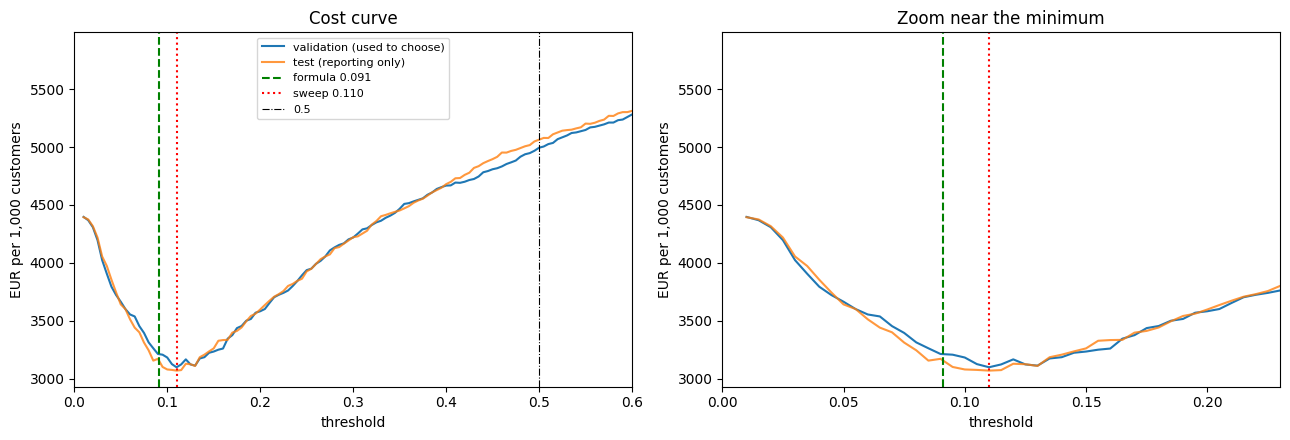

In [9]:
C_FP, C_FN = 5.0, 50.0            # EUR per false positive / false negative
t_formula = C_FP / (C_FP + C_FN)
p_va = pipe_u.predict_proba(X_va)
p_te_u = p_te["unweighted"]
grid = np.round(np.arange(0.01, 0.99, 0.005), 3)

def cost(y, p, t):
    c = confusion(y, p, t)
    return C_FP * c["FP"] + C_FN * c["FN"]

val_cost = np.array([cost(y_va, p_va, t) for t in grid]) / len(y_va) * 1000     # EUR per 1000 customers
te_cost = np.array([cost(y_te, p_te_u, t) for t in grid]) / len(y_te) * 1000
t_sweep = float(grid[val_cost.argmin()])
per1000 = lambda y, p, t: cost(y, p, t) / len(y) * 1000

cost_rows = {
    "formula  c_fp/(c_fp+c_fn)": (t_formula, per1000(y_va, p_va, t_formula), per1000(y_te, p_te_u, t_formula)),
    "validation sweep minimum": (t_sweep, per1000(y_va, p_va, t_sweep), per1000(y_te, p_te_u, t_sweep)),
    "default 0.5": (0.5, per1000(y_va, p_va, 0.5), per1000(y_te, p_te_u, 0.5)),
}
base_rows = {"contact nobody (every subscriber missed)": C_FN * y_te.sum() / len(y_te) * 1000,
             "contact everybody (every non-subscriber called)": C_FP * (1 - y_te).sum() / len(y_te) * 1000}
cost_df = pd.DataFrame(cost_rows, index=["threshold", "validation cost / 1000", "TEST cost / 1000"]).T
print(f"t_formula = {t_formula:.4f}   t_sweep = {t_sweep:.3f}   (costs in EUR per 1,000 customers)")
display(cost_df)
base_rows = {k: float(v) for k, v in base_rows.items()}
print({k: round(v, 1) for k, v in base_rows.items()})

# flatness: how wide is the region within 2% / 5% of the minimum (contiguous around the argmin)?
def region(frac):
    lim, i0 = val_cost.min() * (1 + frac), val_cost.argmin()
    lo = hi = i0
    while lo > 0 and val_cost[lo - 1] <= lim: lo -= 1
    while hi < len(grid) - 1 and val_cost[hi + 1] <= lim: hi += 1
    return grid[lo], grid[hi]
r2, r5 = region(0.02), region(0.05)
def te_at(t): return float(np.interp(t, grid, te_cost))
off = {d: te_at(t_sweep + d) / te_at(t_sweep) - 1 for d in (-0.05, -0.02, 0.02, 0.05) if grid[0] <= t_sweep + d <= grid[-1]}
m02 = max(abs(v) for d, v in off.items() if abs(d) == 0.02)
m05 = max(abs(v) for d, v in off.items() if abs(d) == 0.05)
if m02 < 0.03 and m05 < 0.06:
    flat_text = "**The curve is flat near the minimum: being off by 0.02 costs under 3% and by 0.05 under 6%, so the exact threshold barely matters and the formula and sweep values are interchangeable in practice. The big saving comes from leaving 0.5 behind.**"
elif m02 < 0.03:
    flat_text = f"**The curve is flat within about +/-0.02 of the minimum (under 3% extra cost) but rises steeply further away (up to {m05:.0%} extra cost at +/-0.05), so the threshold only needs to be roughly right; the formula and sweep values are close enough to be interchangeable, but 0.5 is far too high.**"
else:
    flat_text = f"**The curve is fairly sharp near the minimum (up to {m02:.0%} extra cost for being off by just 0.02), so small threshold errors cost real money. The sweep, which sees actual data, should be preferred over the formula, which assumes perfectly calibrated probabilities.**"
print(f"within 2% of min cost: thresholds {r2[0]:.3f}-{r2[1]:.3f} (width {r2[1]-r2[0]:.3f}); within 5%: {r5[0]:.3f}-{r5[1]:.3f}")
print("test cost change if the threshold is off by d:", {f"{d:+.2f}": f"{v:+.1%}" for d, v in off.items()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, xlim in zip(ax, [(0, 0.6), (max(0, t_sweep - 0.12), t_sweep + 0.12)]):
    a.plot(grid, val_cost, label="validation (used to choose)"); a.plot(grid, te_cost, label="test (reporting only)", alpha=.8)
    a.axvline(t_formula, color="g", ls="--", label=f"formula {t_formula:.3f}"); a.axvline(t_sweep, color="r", ls=":", label=f"sweep {t_sweep:.3f}")
    a.axvline(0.5, color="k", ls="-.", lw=.8, label="0.5"); a.set(xlim=xlim, xlabel="threshold", ylabel="EUR per 1,000 customers")
ax[0].set_title("Cost curve"); ax[1].set_title("Zoom near the minimum"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("threshold_cost_curve.png", dpi=140); plt.show()

In [10]:
c05, c_s = confusion(y_te, p_te_u, 0.5), confusion(y_te, p_te_u, t_sweep)
cm = pd.DataFrame({"at 0.5": c05, f"at {t_sweep:.3f} (chosen)": c_s}).T
cm["contacted"] = cm.TP + cm.FP
cm["recall"] = [prf(c05)["recall"], prf(c_s)["recall"]]; cm["precision"] = [prf(c05)["precision"], prf(c_s)["precision"]]
display(cm)

def md_table(d, fmts=None, index_name="", default="{:,.4f}"):
    fmts = fmts or {}
    cols = [index_name] + [str(c) for c in d.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for i, idx in enumerate(d.index):
        cells = []
        for c in d.columns:
            x = d[c].iloc[i]
            if isinstance(x, (int, np.integer)):
                cells.append(f"{x:,}")
            elif isinstance(x, (float, np.floating)):
                cells.append(fmts.get(c, default).format(x))
            else:
                cells.append(str(x))
        out.append("| " + " | ".join([str(idx)] + cells) + " |")
    return "\n".join(out)

N, P_ = len(y_te), int(y_te.sum())
extra_fp, fewer_fn = c_s["FP"] - c05["FP"], c05["FN"] - c_s["FN"]
saving = te_at(0.5) - per1000(y_te, p_te_u, t_sweep)
thr_md = f"""# R6 - The decision threshold (Bank Marketing, term-deposit campaign)

**Use case:** the bank phones customers it expects to subscribe. Predicting positive = "call this customer".

## 1. Costs (assumed figures, justified)
- **False positive = EUR {C_FP:g}.** A false positive is a call to someone who then declines. An outbound call takes roughly 7.5 minutes of agent time at about EUR 40/hour fully loaded, which is about EUR 5 of wasted time (assumption).
- **False negative = EUR {C_FN:g}.** A false negative is a would-be subscriber we never phone. We assume a term deposit earns the bank roughly EUR 50 net margin after servicing, and that margin is simply lost if there is no call (assumption).
- Simplification: only *errors* are costed (as the brief defines cost); the call that reaches a true subscriber is treated as the price of doing business.

## 2. Formula threshold
t* = c_fp / (c_fp + c_fn) = {C_FP:g} / ({C_FP:g} + {C_FN:g}) = **{t_formula:.4f}**. This is optimal only if the probabilities are calibrated; the unweighted model's calibration error on test is {ece['unweighted']:.3f} (see R5), so the formula should be close but not exact.

## 3. Sweep threshold
Sweeping 0.01-0.985 on the **validation** split gives **{t_sweep:.3f}**. We adopt this as the chosen threshold because it is read off real data and does not rely on the probabilities being perfectly calibrated.

## 4. Both thresholds, cost on the TEST split (EUR per 1,000 customers)
{md_table(cost_df, fmts={"threshold": "{:.4f}"}, default="{:,.1f}", index_name="rule")}

Reference points: contacting nobody costs {base_rows['contact nobody (every subscriber missed)']:.1f}; contacting everybody costs {base_rows['contact everybody (every non-subscriber called)']:.1f}.

## 5. The cost curve and how flat it is
![cost curve](threshold_cost_curve.png)

Cost stays within 2% of the validation minimum for thresholds {r2[0]:.3f}-{r2[1]:.3f} (width {r2[1]-r2[0]:.3f}) and within 5% for {r5[0]:.3f}-{r5[1]:.3f}. On the test split, moving the threshold by {", ".join(f"{d:+.2f}" for d in off)} changes cost by {", ".join(f"{v:+.1%}" for v in off.values())} respectively. {flat_text}

## 6. Confusion matrices on the test split (N = {N:,}, {P_} subscribers)
{md_table(cm.astype({"TN": int, "FP": int, "FN": int, "TP": int, "contacted": int}), index_name="threshold")}

**In plain language.** At 0.5 the bank would phone {c05['TP'] + c05['FP']:,} customers ({(c05['TP'] + c05['FP']) / N:.1%}) and reach {c05['TP']} of the {P_} subscribers; {c05['FN']} are missed. At {t_sweep:.3f} it phones {c_s['TP'] + c_s['FP']:,} ({(c_s['TP'] + c_s['FP']) / N:.1%}) and reaches {c_s['TP']}; {c_s['FN']} are missed. That is {fewer_fn:,} fewer missed subscribers at the price of {extra_fp:,} extra calls to people who will say no. It affects the call-centre team (more calls to make), the customers who receive unwanted calls, and the bank, which gains the margin on the extra subscribers: a saving of about EUR {saving:,.1f} per 1,000 customers against the 0.5 default.
"""
open("threshold.md", "w").write(thr_md)
print("threshold.md written")

,TN,FP,FN,TP,contacted,recall,precision
at 0.5,7917,68,909,149,217,0.1408,0.6866
at 0.110 (chosen),5493,2492,306,752,3244,0.7108,0.2318


threshold.md written


## R7 - Class imbalance, compared
Three models: unweighted at 0.5, `class_weight="balanced"` at 0.5, unweighted with the tuned threshold (chosen on validation).

In [11]:
models = {"1 unweighted @0.5": ("unweighted", 0.5), "2 balanced @0.5": ("balanced", 0.5), f"3 unweighted @{t_sweep:.3f} (tuned)": ("unweighted", t_sweep)}
p_va_all = {"unweighted": p_va, "balanced": pipe_b.predict_proba(X_va)}
rows = {}
for nm, (k, t) in models.items():
    c = confusion(y_te, p_te[k], t)
    rows[nm] = {"threshold": t, **{m: prf(c)[m] for m in ("recall", "precision")}, "log-loss": ev[k]["log-loss"], "ECE": ev[k]["ECE"],
                "contacted": c["TP"] + c["FP"], "val cost/1000": per1000(y_va, p_va_all[k], t), "TEST cost/1000": per1000(y_te, p_te[k], t)}
r7 = pd.DataFrame(rows).T
display(r7)
best = r7["val cost/1000"].idxmin()
reason = ("Keeping the model honest about probabilities and moving the threshold to match the costs is the cleaner way to act on an imbalanced problem: the probabilities stay usable and the cut-off encodes the business costs."
          if best.startswith("3") else
          "The reweighted model wins on validation cost here, but only because it happens to push probabilities up toward the cost-optimal cut-off; its probabilities are still distorted, which matters if anyone needs a real risk estimate." if best.startswith("2") else
          "At these costs the default 0.5 is competitive, which is itself a finding: the costs are not lopsided enough to justify moving the threshold.")
print(f"""
Recommendation (use case: decide whom to phone when a wasted call costs EUR {C_FP:g} and a missed subscriber EUR {C_FN:g}):
Use model "{best}", which has the lowest VALIDATION cost ({r7.loc[best, 'val cost/1000']:.1f} per 1,000; its test cost is {r7.loc[best, 'TEST cost/1000']:.1f}).
Models 1 and 3 share the same probabilities (log-loss {r7.iloc[0]['log-loss']:.3f}, ECE {r7.iloc[0]['ECE']:.3f}); only the cut-off differs, so tuning the threshold changes recall/precision without damaging calibration.
Balanced weighting reaches recall {r7.iloc[1]['recall']:.2f} but at log-loss {r7.iloc[1]['log-loss']:.3f} and ECE {r7.iloc[1]['ECE']:.3f}: its probabilities are distorted, so they cannot be used for anything that needs a real probability (ranking by expected value, cost formulas, reporting a risk).
{reason}""")

,threshold,recall,precision,log-loss,ECE,contacted,val cost/1000,TEST cost/1000
1 unweighted @0.5,0.5000,0.1408,0.6866,0.2995,0.0179,217.0000,"4,993.9173","5,063.5851"
2 balanced @0.5,0.5000,0.6399,0.2637,0.5597,0.3038,"2,567.0000","3,163.0170","3,151.6090"
3 unweighted @0.110 (tuned),0.1100,0.7108,0.2318,0.2995,0.0179,"3,244.0000","3,098.8719","3,069.7777"



Recommendation (use case: decide whom to phone when a wasted call costs EUR 5 and a missed subscriber EUR 50):
Use model "3 unweighted @0.110 (tuned)", which has the lowest VALIDATION cost (3098.9 per 1,000; its test cost is 3069.8).
Models 1 and 3 share the same probabilities (log-loss 0.299, ECE 0.018); only the cut-off differs, so tuning the threshold changes recall/precision without damaging calibration.
Balanced weighting reaches recall 0.64 but at log-loss 0.560 and ECE 0.304: its probabilities are distorted, so they cannot be used for anything that needs a real probability (ranking by expected value, cost formulas, reporting a risk).
Keeping the model honest about probabilities and moving the threshold to match the costs is the cleaner way to act on an imbalanced problem: the probabilities stay usable and the cut-off encodes the business costs.


## README

In [ ]:
open("README.md", "w").write(
"1. Open analysis.ipynb in Google Colab -> Runtime -> Run all (needs numpy, pandas, scikit-learn, matplotlib; downloads Bank Marketing from OpenML).\n"
"2. It writes logistic.py and test_logistic.py, then runs `python3 test_logistic.py` (R1 error cases, stability, R2 gradient check).\n"
"3. It then writes reconciliation.md (R3), threshold.md + threshold_cost_curve.png (R6) and prints R4, R5, R7 results; seed = 42 everywhere.\n"
"4. Submit logistic.py, test_logistic.py, reconciliation.md, analysis.ipynb, threshold.md (+ the png) and this README.\n")
print(open("README.md").read())